-------
## Projekt 1 - Wstęp do Uczenia Maszynowego 2026Z

## Kod KM1

-------


**Imię i Nazwisko:** Paweł Buczyński

**Prowadzący:** AK

**Kierunek:** IAD

**Numer albumu:** 338979

------

> Proszę o dostosowanie nazw rozdziałów i podrozdziałów do nazw umieszczonych w raporcie.

### *Import pakietów*

-------

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn import tree
from sklearn.model_selection import KFold, RepeatedKFold, cross_val_score, train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score

In [40]:
import itertools
from tqdm import tqdm

### *1. Eksploracyjna analiza danych*
-------

In [9]:
X_train = pd.read_csv("X_train.csv")
X_test = pd.read_csv("X_test.csv")
y_train = pd.read_csv("y_train.csv")
X_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 6400 entries, 0 to 6399
Data columns (total 23 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   LIMIT_BAL  6400 non-null   float64
 1   SEX        6400 non-null   int64  
 2   EDUCATION  6400 non-null   int64  
 3   MARRIAGE   6400 non-null   int64  
 4   AGE        6400 non-null   int64  
 5   PAY_0      6400 non-null   int64  
 6   PAY_2      6400 non-null   int64  
 7   PAY_3      6400 non-null   int64  
 8   PAY_4      6400 non-null   int64  
 9   PAY_5      5764 non-null   float64
 10  PAY_6      6400 non-null   int64  
 11  BILL_AMT1  6400 non-null   float64
 12  BILL_AMT2  6400 non-null   float64
 13  BILL_AMT3  6400 non-null   float64
 14  BILL_AMT4  6400 non-null   float64
 15  BILL_AMT5  6400 non-null   float64
 16  BILL_AMT6  5747 non-null   float64
 17  PAY_AMT1   6400 non-null   float64
 18  PAY_AMT2   6400 non-null   float64
 19  PAY_AMT3   6400 non-null   float64
 20  PAY_AMT4   5765 non

In [11]:
y_train

,default.payment.next.month
0,1
1,0
2,0
3,0
4,0
...,...
6395,1
6396,0
6397,1
6398,0


In [3]:
X_train.rename(columns={"PAY_0": "PAY_1"}, inplace=True)

In [4]:
X_train.describe()

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
count,6400.000000,6400.000000,6400.000000,6400.000000,6400.000000,6400.000000,6400.000000,6400.000000,6400.000000,5764.000000,...,6400.000000,6400.000000,6400.000000,5747.000000,6400.000000,6400.000000,6400.000000,5765.000000,6400.000000,6400.000000
mean,167058.277002,1.600781,1.837344,1.565313,34.828437,-0.016875,-0.147813,-0.165469,-0.229687,-0.277412,...,46668.658987,42570.465505,39376.521125,38299.316665,5915.514595,5880.763194,5467.802412,4885.008345,5095.018971,5683.631062
std,130788.623708,0.489776,0.796703,0.518858,9.090674,1.132852,1.179351,1.189615,1.158643,1.122036,...,69070.541625,63682.290146,59482.257375,59008.762193,16238.050622,18325.748442,16933.338728,16338.827889,16667.879638,20156.367699
min,-157.510827,1.000000,0.000000,0.000000,19.000000,-2.000000,-2.000000,-3.000000,-2.000000,-2.000000,...,-31630.644835,-55474.962574,-35278.286793,-233709.690512,-6738.564949,-10167.637159,-7045.833855,-7348.718103,-5067.446251,-6447.078871
25%,54027.835110,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,4985.879564,4228.746666,3888.382113,3240.553965,831.049893,590.110451,471.693831,316.222230,363.164390,315.556262
50%,138508.702518,2.000000,2.000000,2.000000,33.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,21111.898181,19429.490212,17977.085430,17057.197383,2488.564978,2435.121810,1963.011326,1690.255004,1768.453638,1765.101581
75%,236847.697924,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,59476.042972,53533.843872,49679.867123,48644.156400,5589.821721,5579.007592,4841.167174,4331.011086,4436.389159,4500.501201
max,783258.369189,2.000000,6.000000,3.000000,73.000000,8.000000,7.000000,7.000000,7.000000,7.000000,...,548472.305856,536004.787076,502351.970698,496311.167092,306664.791220,579958.411614,402667.936174,432461.892791,328741.932673,527618.450542


In [5]:
X_train.head()

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
0,19912.825563,2,2,1,44,2,0,0,2,2.0,...,23094.542467,17974.686955,18841.431580,15783.245882,1423.110120,3049.157007,157.071859,733.154414,478.947062,379.984156
1,55043.974658,1,1,2,24,4,4,4,4,3.0,...,36533.557269,38224.238356,39238.101886,40576.008942,2037.243581,1854.121994,300.752767,1020.891555,-455.518882,2469.448131
2,20006.277688,2,2,2,31,0,0,0,0,NaN,...,22411.774647,28966.654890,19049.390827,15402.347969,10175.669342,4573.613449,-771.581797,-283.002435,4857.385369,3474.203409
3,128698.125632,1,1,2,31,-1,-1,-1,-2,-2.0,...,-2138.872526,-2834.834778,-786.605171,49261.032919,10858.685707,1101.369070,25.587625,-331.783255,49191.348594,3767.305856
4,358711.329669,2,1,1,34,-2,-2,-2,-2,-2.0,...,15059.484302,16441.809554,14173.086443,21134.235164,6945.506312,691.104497,7333.776096,5973.950428,5218.051932,28455.969902


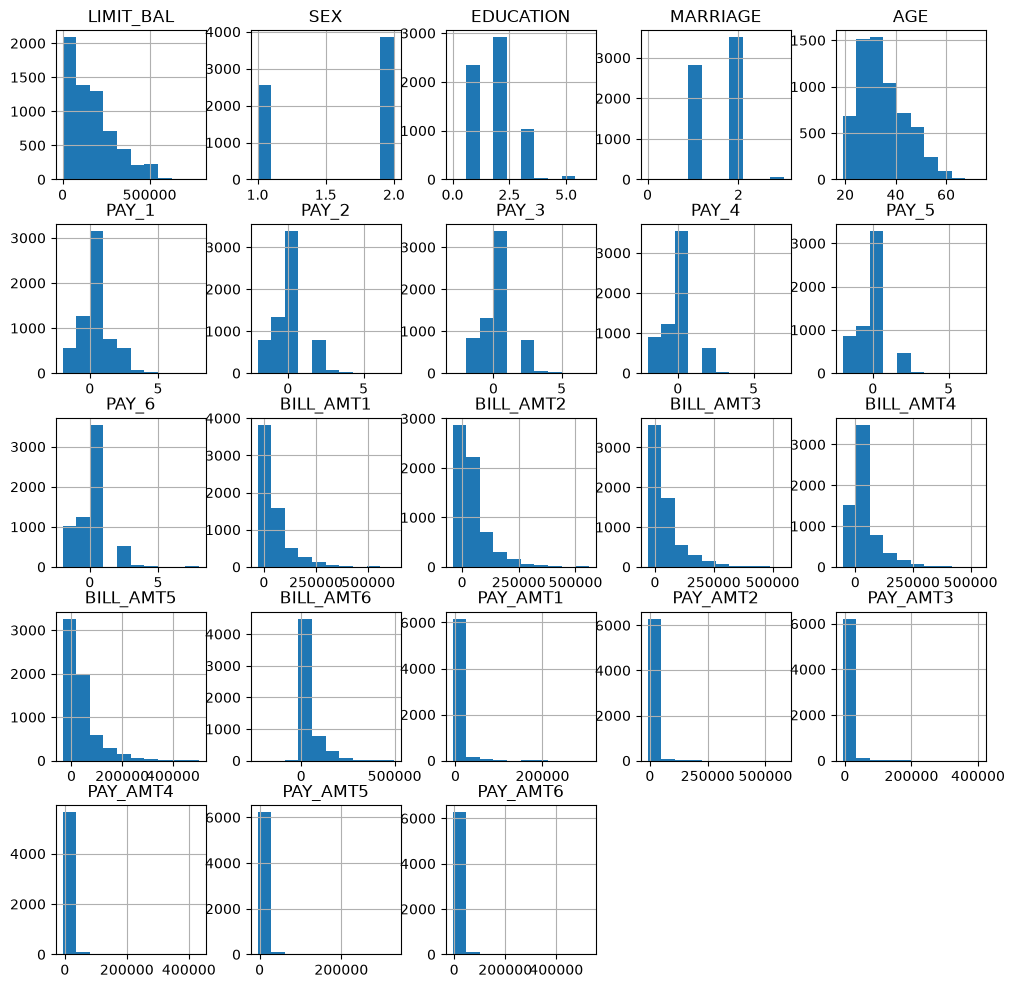

In [6]:
X_train.hist(figsize=(12, 12));

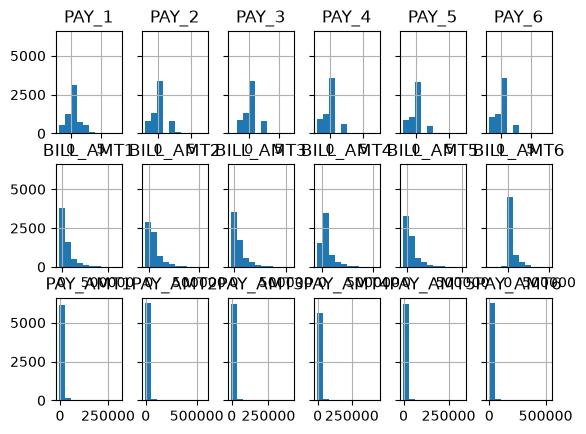

In [7]:
pay_cols = [f"PAY_{i}" for i in range(1, 7)]
bill_amt_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
pay_amt_cols = [f"PAY_AMT{i}" for i in range(1, 7)]

X_train[pay_cols + bill_amt_cols + pay_amt_cols].hist(layout=(3, 6), sharey=True);

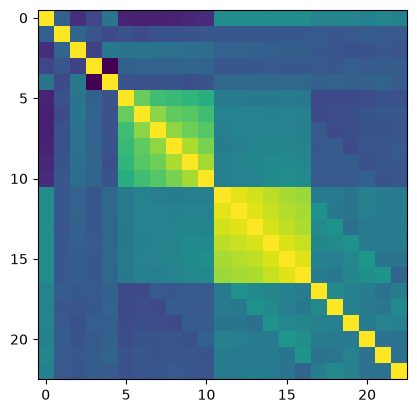

In [8]:
plt.imshow(X_train.corr())

### *1.1 Podrozdział 1 (edit)*
-------

### *2. Metryka ewaluacji i podział danych*
-------

In [15]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.20, random_state=123
)
cv = KFold(n_splits=10, shuffle=True, random_state=123)

In [ ]:
params = {
    "criterion": ["gini", "entropy"],
    "max_depth": np.arange(2, 20, 1),
    "max_leaf_nodes": np.arange(10, 30, 1),
}

total = np.prod(list(map(len, params.values())))
print(total, list(map(len, params.values())))

720 [2, 18, 20]


In [ ]:
product = (dict(zip(params, mp)) for mp in itertools.product(*params.values()))

results = []
for params in tqdm(product, total=total):
    model = tree.DecisionTreeClassifier(**params, random_state=123)
    scores = cross_val_score(model, X_fit, y_fit, cv=cv, n_jobs=24, scoring="roc_auc")
    results.append({**params, "score": np.mean(scores)})

100%|██████████| 720/720 [01:09<00:00, 10.37it/s]


In [ ]:
df = pd.DataFrame(results)

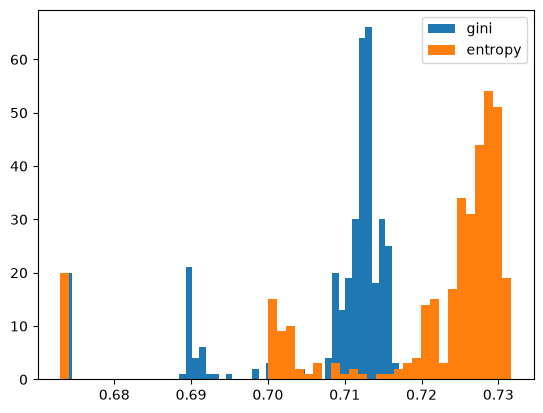

In [148]:
for c in params["criterion"]:
    plt.hist(df.loc[df["criterion"] == c, "score"], label=c, bins=50)
plt.legend()

np.float64(0.7316730728395714)

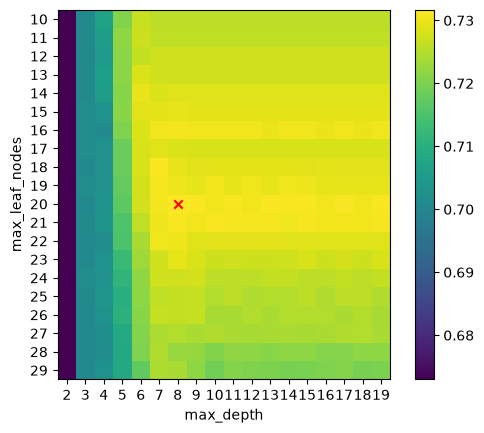

In [130]:
data = df[df["criterion"] == "entropy"].pivot(index="max_leaf_nodes", columns="max_depth", values="score").to_numpy()
maximum = np.unravel_index(np.argmax(data), shape=data.shape)
plt.imshow(data)
plt.scatter(*maximum[::-1], marker="x", color="red")
plt.xlabel("max_depth")
plt.ylabel("max_leaf_nodes")
plt.xticks(np.arange(len(params["max_depth"])), params["max_depth"])
plt.yticks(np.arange(len(params["max_leaf_nodes"])), params["max_leaf_nodes"])
plt.colorbar()
plt.clim(np.min(data), np.max(data))
data[maximum]

In [131]:
best = df.iloc[df["score"].idxmax()]
best

criterion          entropy
max_depth                8
max_leaf_nodes          20
score             0.731673
Name: 490, dtype: object

In [ ]:
model = tree.DecisionTreeClassifier(**best[["criterion", "max_depth", "max_leaf_nodes"]])
model.fit(X_fit, y_fit)

### *2.1 Podrozdział 2 (edit)*
-------

### *3. Podsumowanie i wnioski*
-------